# Day 2: Positional Encoding in Transformers

In [11]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.layers import TextVectorization

In [12]:
def positional_encoding(seq_len,d_model):
  pos = np.arange(seq_len)[:,np.newaxis]
  i = np.arange(d_model)[np.newaxis,:]
  angle_rate = 1/np.power(
      1000,
      (2*(i//1))/np.float32(d_model)
  )
  angle_rads = pos*angle_rate

  angle_rads[:,0::2] = np.sin(
      angle_rads[:,0::2]
  )

  angle_rads[:,1::2] = np.cos(
      angle_rads[:,1::2]
  )

  return tf.cast(angle_rads[np.newaxis,...],
                 dtype = tf.float32)

In [13]:
seq_len = 10
d_model = 16

pos_encoding = positional_encoding(
    seq_len,
    d_model
)

print(pos_encoding.shape)

(1, 10, 16)


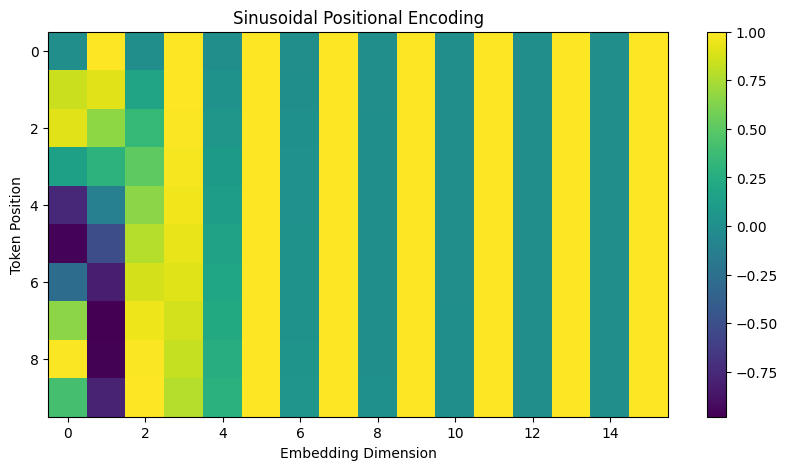

In [14]:
plt.figure(figsize = (10,5))

plt.imshow(pos_encoding[0].numpy(),aspect = "auto")
plt.xlabel("Embedding Dimension")
plt.ylabel("Token Position")
plt.title("Sinusoidal Positional Encoding")
plt.colorbar()

plt.show()

In [29]:
sentences = [
    "I love machine learning",
    "Transformers understand language"
]
tokenizer = TextVectorization(
    output_mode = "int",
    output_sequence_length = 10
)
tokenizer.adapt(sentences)

text = tf.constant(sentences)
token_ids = tokenizer(text)

In [30]:
embedding_layer = tf.keras.layers.Embedding(
    input_dim = len(tokenizer.get_vocabulary()),
    output_dim = 16,
    mask_zero = True
)

In [31]:
embeddings = embedding_layer(token_ids)

In [32]:
pos_encoding = positional_encoding(
    seq_len=10,
    d_model=16
)

In [33]:
final_embeddings = embeddings + pos_encoding

In [36]:
print("token id shapes",token_ids.shape)
print("embedding layer shape",embeddings.shape)
print("positional layer shape",pos_encoding.shape)
print("final embedding shape",final_embeddings.shape)

token id shapes (2, 10)
embedding layer shape (2, 10, 16)
positional layer shape (1, 10, 16)
final embedding shape (2, 10, 16)
